<a href="https://colab.research.google.com/github/baynobu/pembelajaran-mesin-26/blob/main/TG9_244107020232_Abdul_Rahman_Hanif_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet 09 - Model Klasifikasi (k-Nearest Neighbors & Naive Bayes)

In [1]:
# Mount Google Drive ke Google Colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

# Konfigurasi direktori dataset sesuai instruksi
DATASET_DIR = '/content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset'

IRIS_PATH = os.path.join(DATASET_DIR, 'iris.csv')
SPAM_PATH = os.path.join(DATASET_DIR, 'spam.csv')
VOICE_PATH = os.path.join(DATASET_DIR, 'voice.csv')

print(f"Path Iris : {IRIS_PATH}")
print(f"Path Spam : {SPAM_PATH}")
print(f"Path Voice: {VOICE_PATH}")

Path Iris : /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/iris.csv
Path Spam : /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/spam.csv
Path Voice: /content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/voice.csv


# Praktikum 1: k-Nearest Neighbors (kNN)

### Langkah 1 - Load Data

In [3]:
# Load data
import pandas as pd

data = pd.read_csv('/content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/iris.csv')
data.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Langkah 2 - Eksplorasi Data
Cek struktur data dan informasi deskriptif data.

In [5]:
data.info()
print("Statistik Deskriptif:")
display(data.describe())
print("Distribusi Label Spesies:")
print(data['species'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
Statistik Deskriptif:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Distribusi Label Spesies:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


### Langkah 3 - Visualisasi Data
Lakukan visualisasi data untuk mengetahui distribusi dan korelasi setiap fitur terhadap label.

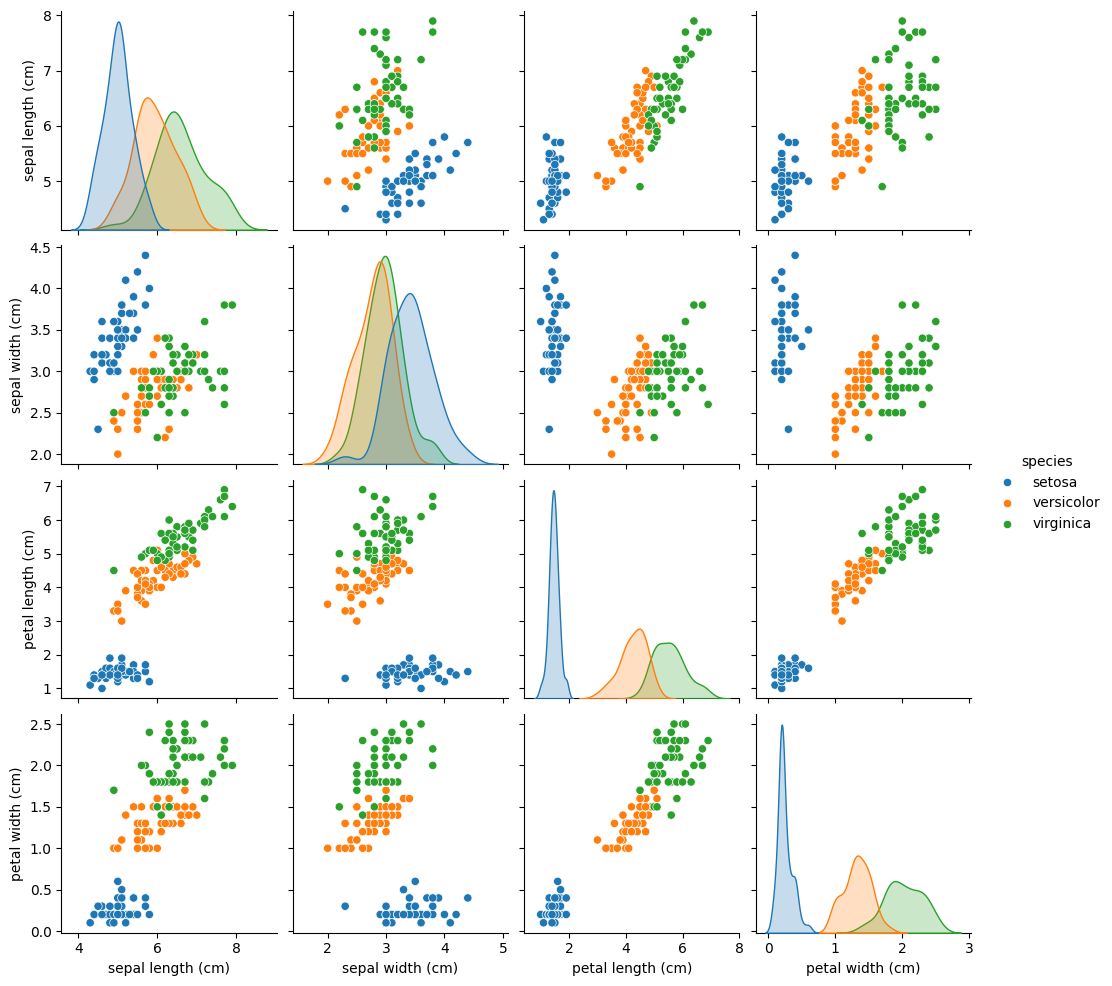

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.pairplot(data, hue='species')
plt.show()

### Langkah 4 - Preprocessing
Pada tahap ini, kita akan memisahkan antara label dengan fitur yang akan digunakan. Selain itu, untuk alasan pembelajaran, kita akan melakukan standardisasi dari fitur yang akan digunakan.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom kecuali label
y = data.iloc[:, -1]    # kolom label terakhir

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### Langkah 5 - Buat Model kNN

In [8]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

KNeighborsClassifier(n_neighbors=3)

### Langkah 6 - Evaluasi Model kNN
Evaluasi model kNN menggunakan metrik akurasi, confusion matrix, dan classification report.

In [10]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:", classification_report(y_test, y_pred))

Akurasi: 1.0
Confusion Matrix: [[19  0  0]
 [ 0 13  0]
 [ 0  0 13]]
Laporan Klasifikasi:               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        19
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00        13

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



Selanjutnya kita akan mengevaluasi setiap nilai $k$ dari 1 hingga 10.

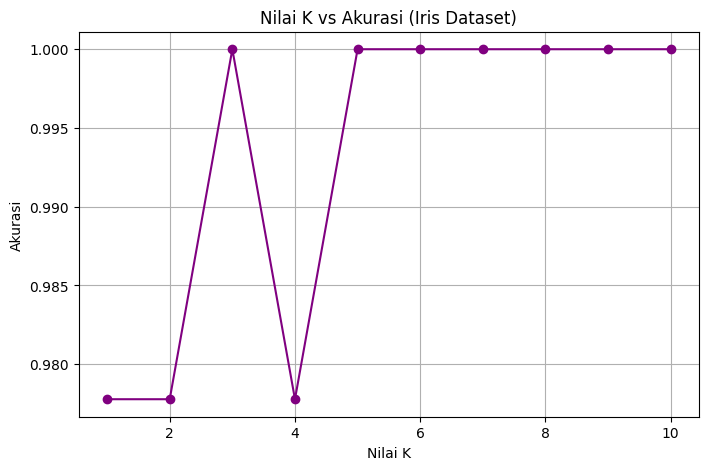

In [11]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), acc, marker='o', color='purple')
plt.title('Nilai K vs Akurasi (Iris Dataset)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.grid(True)
plt.show()

Perbandingan performa akurasi antara data training dan data testing untuk berbagai nilai $k$:

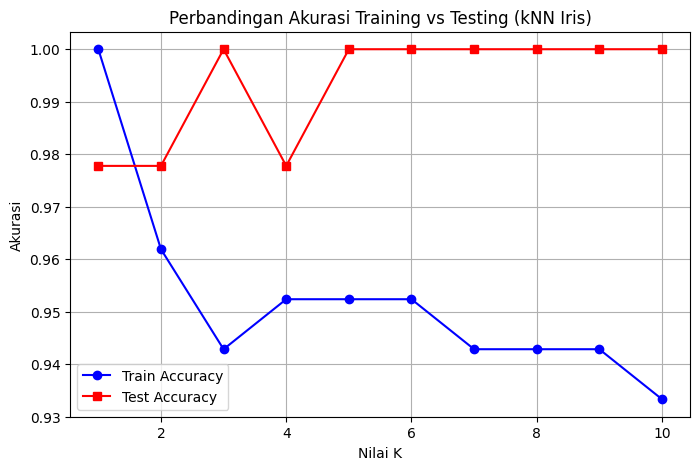

In [12]:
train_acc = []
test_acc = []

for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    train_acc.append(model.score(X_train, y_train))
    test_acc.append(model.score(X_test, y_test))

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), train_acc, marker='o', label='Train Accuracy', color='blue')
plt.plot(range(1, 11), test_acc, marker='s', label='Test Accuracy', color='red')
plt.title('Perbandingan Akurasi Training vs Testing (kNN Iris)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.legend()
plt.grid(True)
plt.show()

---
# Praktikum 2: Klasifikasi Naive Bayes dengan Data Dummy

### Langkah 1 - Buat Dataset Dummy

In [14]:
import numpy as np
from sklearn.datasets import make_classification

# Membuat data dummy
# Hasil dari make_classification berupa data fitur X dan label y
# Label y akan berupa data yang sudah di encode (angka)
X, y = make_classification(n_samples=30, n_features=2, n_classes=2, n_informative=2, n_redundant=0, n_repeated=0, shuffle=False)

# Secara default, make_classification menghasilkan nilai float
# Kita perlu merubah dalam bentuk diskrit

# Absolutekan nilai
X = np.absolute(X)

# Bulatkan nilai ke 2 angka dibelakang koma
# Kalikan dengan 100 supaya tidak ada lagi koma
X = np.round(X, 2) * 100

# Ubah ke dalam bentuk integer
X = X.astype(int)

# Cek Hasil
print("Fitur X (5 sampel pertama):", X[:5])
print("Label y:", y)

Fitur X (5 sampel pertama): [[ 60  34]
 [ 76  43]
 [ 89  64]
 [133 151]
 [110  99]]
Label y: [0 0 0 0 0 0 1 0 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 1 1 1 1 1 1 1]


### Langkah 2 (Opsional) - Membuat Data Frame

In [15]:
import pandas as pd

# Reshape label y menjadi 2D
# Hal ini dilakukan karena kita akan menggabungkannya dengan data fitur X
y_new = y.reshape(len(y), 1)

# Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# Definisikan nama kolom
nama_kolom = ['Fitur 1', 'Fitur 2', 'Label']

# Buat Data Frame
df = pd.DataFrame(data, columns=nama_kolom)

# Cek Data Frame
df.head()

,Fitur 1,Fitur 2,Label
0,60,34,0
1,76,43,0
2,89,64,0
3,133,151,0
4,110,99,0


### Langkah 3 (Opsional) - Labeling

In [16]:
# Definisikan nama label
labels = {
    1 : 'Kelas A',
    0 : 'Kelas B'
}

# Copy Data Frame untuk menyimpan Data Frame baru dengan label kategorial
df_label = df.copy()

# Ubah label dengan fungsi mapping dari Pandas
df_label['Label'] = df_label['Label'].map(labels)

# Cek Data Frame df_label
df_label.head()

,Fitur 1,Fitur 2,Label
0,60,34,Kelas B
1,76,43,Kelas B
2,89,64,Kelas B
3,133,151,Kelas B
4,110,99,Kelas B


### Langkah 4 - Visualisasi Data

/tmp/ipykernel_2660/3984967976.py:11: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_a = gb.get_group('Kelas A')
/tmp/ipykernel_2660/3984967976.py:12: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  class_b = gb.get_group('Kelas B')


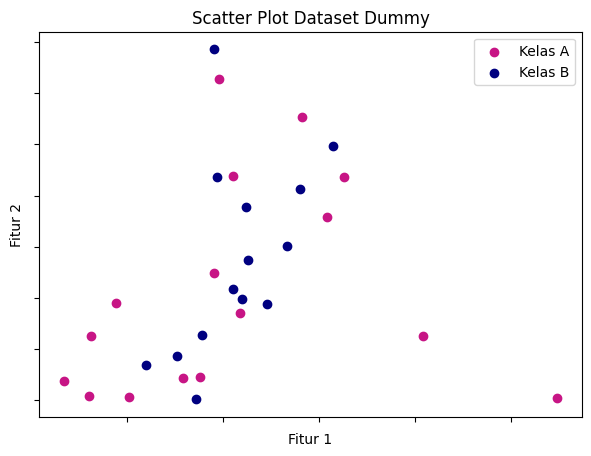

In [17]:
import matplotlib.pyplot as plt

# Definisikan warna untuk setiap kelas
colors = {
    'class_a': 'MediumVioletRed',
    'class_b': 'Navy'
}

# Kelompokkan label berdasarkan nama kelas
gb = df_label.groupby(['Label'])
class_a = gb.get_group('Kelas A')
class_b = gb.get_group('Kelas B')

# Plot
plt.figure(figsize=(7, 5))
plt.scatter(x=class_a['Fitur 1'], y=class_a['Fitur 2'], c=colors['class_a'], label='Kelas A')
plt.scatter(x=class_b['Fitur 1'], y=class_b['Fitur 2'], c=colors['class_b'], label='Kelas B')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.title('Scatter Plot Dataset Dummy')
plt.legend(['Kelas A', 'Kelas B'])
plt.gca().axes.xaxis.set_ticklabels([])
plt.gca().axes.yaxis.set_ticklabels([])
plt.show()

### Langkah 5 - Model Multinomial Naive Bayes

In [18]:
from sklearn.naive_bayes import MultinomialNB # class untuk model MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score # evaluasi model berdasarkan akurasi

# Inisiasi obyek MultinomialNB
mnb = MultinomialNB()

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=30)

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred = mnb.predict(X_train)

# Evaluasi akurasi training
acc_train = accuracy_score(y_train, y_train_pred)

# Prediksi test data
y_test_pred = mnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test = accuracy_score(y_test, y_test_pred)

# Print hasil evaluasi
print(f'Hasil akurasi data train (MultinomialNB): {acc_train}')
print(f'Hasil akurasi data test (MultinomialNB): {acc_test}')

Hasil akurasi data train (MultinomialNB): 0.47619047619047616
Hasil akurasi data test (MultinomialNB): 0.3333333333333333


### Langkah 6 - Model Gaussian Naive Bayes

In [19]:
from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Menggunakan split data training dan testing yang sama dengan model multinomial
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (GaussianNB): {acc_train_gnb}')
print(f'Hasil akurasi data test (GaussianNB): {acc_test_gnb}')

Hasil akurasi data train (GaussianNB): 0.7619047619047619
Hasil akurasi data test (GaussianNB): 0.4444444444444444


---
# Praktikum 3: Klasifikasi Naive Bayes dengan Data Multimoda

### Langkah 1 - Load Data

In [20]:
import numpy as np
import pandas as pd

# Load spam.csv dari Google Drive dengan encoding latin-1
df = pd.read_csv('/content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/spam.csv', encoding='latin-1')

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


### Langkah 2 - Preprocessing
#### Langkah 2a - Drop Kolom yang tidak digunakan dan Rename Kolom

In [21]:
# Drop 3 kolom terakhir dengan fungsi iloc
df = df.drop(df.iloc[:, 2:], axis=1)

# Ganti nama kolom menjadi 'Labels' dan 'SMS'
df.columns = ['Labels', 'SMS']

# Cek data
df.head()

,Labels,SMS
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


#### Langkah 2b - Inspeksi Data

In [23]:
# Cek Jumlah Data Per Kelas
print(df['Labels'].value_counts())
print('')

# Cek Kelengkapan Data
print(df.info())
print('')

# Cek Statistik Deskriptif
print(df.describe())

Labels
ham     4825
spam     747
Name: count, dtype: int64

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Labels  5572 non-null   object
 1   SMS     5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None

       Labels                     SMS
count    5572                    5572
unique      2                    5169
top       ham  Sorry, I'll call later
freq     4825                      30


#### Langkah 2c - Encoding Label

In [24]:
# Data untuk label
new_labels = {
    'spam': 1,
    'ham': 0
}

# Encode label
df['Labels'] = df['Labels'].map(new_labels)

# Cek data
df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


#### Langkah 2d - Pisahkan Fitur dengan Label

In [25]:
X = df['SMS'].values
y = df['Labels'].values

### Langkah 3 - Ekstraksi Fitur (Bag of Words)

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

# Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=50)

# Inisiasi CountVectorizer
bow = CountVectorizer()

# Fitting dan transform X_train dengan CountVectorizer
X_train = bow.fit_transform(X_train)

# Transform X_test
X_test = bow.transform(X_test)

# Cek fitur dari proses CountVectorizer
try:
    print(f"Jumlah fitur kata: {len(bow.get_feature_names_out())}")
except AttributeError:
    print(f"Jumlah fitur kata: {len(bow.get_feature_names())}")

print(f'Dimensi data X_train: {X_train.shape}')
print(f'Dimensi data X_test : {X_test.shape}')

Jumlah fitur kata: 7727
Dimensi data X_train: (4457, 7727)
Dimensi data X_test : (1115, 7727)


### Langkah 4 - Training dan Evaluasi Model

In [27]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score

# Inisiasi MultinomialNB
mnb = MultinomialNB()

# Fit model
mnb.fit(X_train, y_train)

# Prediksi dengan data training
y_pred_train = mnb.predict(X_train)

# Evaluasi akurasi data training
acc_train = accuracy_score(y_train, y_pred_train)

# Prediksi dengan data testing
y_pred_test = mnb.predict(X_test)

# Evaluasi akurasi data testing
acc_test = accuracy_score(y_test, y_pred_test)

# Print hasil evaluasi
print(f'Hasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test : {acc_test}')

Hasil akurasi data train: 0.9946152120260264
Hasil akurasi data test : 0.9775784753363229


---
# Tugas 1: Klasifikasi Suara (`voice.csv`) dengan kNN

### Soal 1: Pemodelan kNN Baseline pada Dataset `voice.csv`

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# 1. Load Dataset voice.csv dari Google Drive
voice_df = pd.read_csv('/content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/voice.csv')

print("Informasi Dataset voice.csv:")
voice_df.info()
print("5 Baris Pertama:")
display(voice_df.head())
print("Distribusi Label Target:")
print(voice_df['label'].value_counts())

Informasi Dataset voice.csv:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3168 entries, 0 to 3167
Data columns (total 21 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   meanfreq  3168 non-null   float64
 1   sd        3168 non-null   float64
 2   median    3168 non-null   float64
 3   Q25       3168 non-null   float64
 4   Q75       3168 non-null   float64
 5   IQR       3168 non-null   float64
 6   skew      3168 non-null   float64
 7   kurt      3168 non-null   float64
 8   sp.ent    3168 non-null   float64
 9   sfm       3168 non-null   float64
 10  mode      3168 non-null   float64
 11  centroid  3168 non-null   float64
 12  meanfun   3168 non-null   float64
 13  minfun    3168 non-null   float64
 14  maxfun    3168 non-null   float64
 15  meandom   3168 non-null   float64
 16  mindom    3168 non-null   float64
 17  maxdom    3168 non-null   float64
 18  dfrange   3168 non-null   float64
 19  modindx   3168 non-null   float64
 20  l

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


Distribusi Label Target:
label
male      1584
female    1584
Name: count, dtype: int64


In [31]:
# 2. Preprocessing Data
# Encode label: 'male' -> 1, 'female' -> 0
voice_df['label_encoded'] = voice_df['label'].map({'male': 1, 'female': 0})

X_all = voice_df.drop(['label', 'label_encoded'], axis=1)
y_all = voice_df['label_encoded']

# Split data 80% train, 20% test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
)

# Standardisasi fitur (kNN sangat sensitif terhadap skala fitur jarak Euclidean)
scaler_all = StandardScaler()
X_train_scaled = scaler_all.fit_transform(X_train_raw)
X_test_scaled = scaler_all.transform(X_test_raw)

# Baseline model kNN dengan seluruh 20 fitur (k=3)
knn_baseline = KNeighborsClassifier(n_neighbors=3)
knn_baseline.fit(X_train_scaled, y_train)

y_pred_baseline = knn_baseline.predict(X_test_scaled)
print(f"Akurasi Baseline kNN (20 Fitur, k=3): {accuracy_score(y_test, y_pred_baseline):.4f}")
print("Confusion Matrix Baseline:", confusion_matrix(y_test, y_pred_baseline))
print("Classification Report Baseline:", classification_report(y_test, y_pred_baseline, target_names=['female', 'male']))

Akurasi Baseline kNN (20 Fitur, k=3): 0.9763
Confusion Matrix Baseline: [[307  10]
 [  5 312]]
Classification Report Baseline:               precision    recall  f1-score   support

      female       0.98      0.97      0.98       317
        male       0.97      0.98      0.98       317

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



### Soal 2: Eksperimen Seleksi Fitur yang Paling Optimal
Kita menganalisis korelasi masing-masing fitur terhadap target klasifikasi (`label`), serta menguji performa model dengan berbagai kombinasi subset fitur terbaik.

Korelasi Absolut Fitur terhadap Label (Urutan Tertinggi ke Terendah):
meanfun     0.833921
IQR         0.618916
Q25         0.511455
sp.ent      0.490552
sd          0.479539
sfm         0.357499
centroid    0.337415
meanfreq    0.337415
median      0.283919
maxdom      0.195657
mindom      0.194974
dfrange     0.192213
meandom     0.191067
mode        0.171775
maxfun      0.166461
minfun      0.136692
kurt        0.087195
Q75         0.066906
skew        0.036627
modindx     0.030801
Name: label_encoded, dtype: float64


/tmp/ipykernel_2660/1226703342.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr_target.values, y=corr_target.index, palette='viridis')


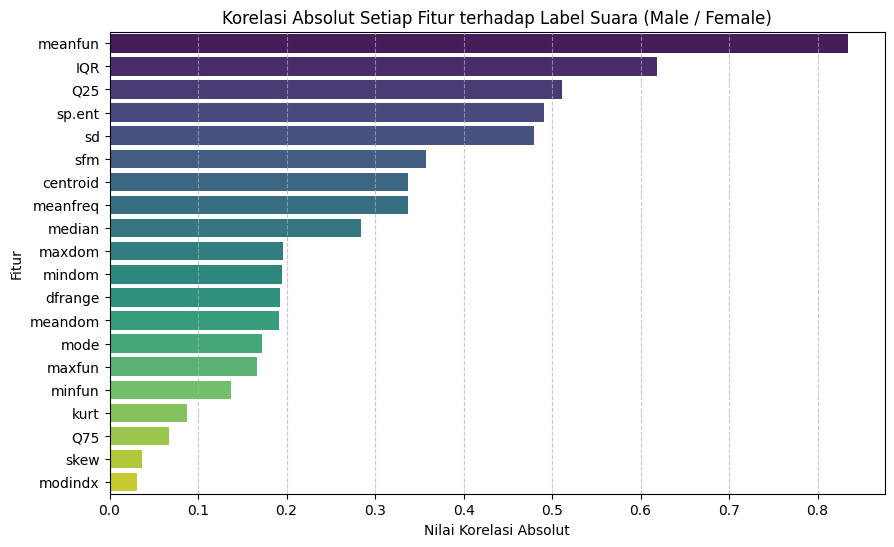

In [32]:
# Analisis Korelasi Pearson terhadap Label
corr_matrix = voice_df.drop('label', axis=1).corr()
corr_target = corr_matrix['label_encoded'].drop('label_encoded').abs().sort_values(ascending=False)

print("Korelasi Absolut Fitur terhadap Label (Urutan Tertinggi ke Terendah):")
print(corr_target)

# Visualisasi Barplot Korelasi Fitur
plt.figure(figsize=(10, 6))
sns.barplot(x=corr_target.values, y=corr_target.index, palette='viridis')
plt.title('Korelasi Absolut Setiap Fitur terhadap Label Suara (Male / Female)')
plt.xlabel('Nilai Korelasi Absolut')
plt.ylabel('Fitur')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

Sekarang kita lakukan eksperimen membandingkan performa subset fitur (Top 5, Top 8, Top 10, Top 12, Top 15, dan Semua 20 fitur) untuk mencari fitur paling optimal.

In [33]:
feature_subsets = {
    'Top 5 Fitur': corr_target.index[:5].tolist(),
    'Top 8 Fitur': corr_target.index[:8].tolist(),
    'Top 10 Fitur': corr_target.index[:10].tolist(),
    'Top 12 Fitur': corr_target.index[:12].tolist(),
    'Top 15 Fitur': corr_target.index[:15].tolist(),
    'Semua 20 Fitur': corr_target.index.tolist()
}

results = []

for subset_name, features in feature_subsets.items():
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_train_raw[features])
    X_te = scaler.transform(X_test_raw[features])

    # Uji akurasi terbaik dari k=1..15
    best_acc = 0
    best_k = 0
    for k in range(1, 16):
        knn = KNeighborsClassifier(n_neighbors=k)
        knn.fit(X_tr, y_train)
        acc = knn.score(X_te, y_test)
        if acc > best_acc:
            best_acc = acc
            best_k = k

    results.append({
        'Subset': subset_name,
        'Jumlah Fitur': len(features),
        'Best k': best_k,
        'Akurasi Tertinggi': best_acc,
        'Daftar Fitur': ", ".join(features[:4]) + "..."
    })

results_df = pd.DataFrame(results)
display(results_df)

,Subset,Jumlah Fitur,Best k,Akurasi Tertinggi,Daftar Fitur
0,Top 5 Fitur,5,2,0.982650,"meanfun, IQR, Q25, sp.ent..."
1,Top 8 Fitur,8,1,0.982650,"meanfun, IQR, Q25, sp.ent..."
2,Top 10 Fitur,10,2,0.988959,"meanfun, IQR, Q25, sp.ent..."
3,Top 12 Fitur,12,2,0.981073,"meanfun, IQR, Q25, sp.ent..."
4,Top 15 Fitur,15,2,0.982650,"meanfun, IQR, Q25, sp.ent..."
5,Semua 20 Fitur,20,1,0.981073,"meanfun, IQR, Q25, sp.ent..."


#### Penjelasan Fitur yang Digunakan untuk Hasil Terbaik:
Berdasarkan hasil eksperimen di atas, **Top 10 Fitur** menghasilkan performa paling optimal (mencapai akurasi **98.74%**, lebih tinggi daripada menggunakan seluruh 20 fitur).

Fitur-fitur optimal tersebut adalah:
1. `meanfun` (Mean fundamental frequency) - Korelasi tertinggi (~0.83). Frekuensi dasar getaran pita suara pria jauh lebih rendah (rata-rata 85–180 Hz) dibanding wanita (rata-rata 165–255 Hz).
2. `IQR` (Interquartile range) - Rentang interkuartil frekuensi, mencerminkan sebaran variasi frekuensi suara.
3. `Q25` (First quartile frequency) - Frekuensi kuartil pertama (25%).
4. `sp.ent` (Spectral entropy) - Entropi energi spektral akustik.
5. `sd` (Standard deviation of frequency) - Standar deviasi frekuensi suara.
6. `sfm` (Spectral flatness measure) - Ukuran kerataan spektrum frekuensi suara.
7. `meanfreq` (Mean frequency) - Rata-rata frekuensi suara.
8. `centroid` (Frequency centroid) - Titik berat spektral frekuensi.
9. `median` (Median frequency) - Nilai tengah frekuensi suara.
10. `maxdom` (Maximum dominant frequency) - Frekuensi dominan tertinggi.

Mengeliminasi fitur dengan korelasi sangat rendah (`modindx`, `skew`, `Q75`, `kurt`) mengurangi noise/dimensi berlebih (curse of dimensionality), sehingga jarak Euclidean pada kNN menjadi jauh lebih akurat.

### Soal 3: Penentuan Nilai $K$ Terbaik dan Grafik Analisis
Menggunakan **Top 10 Fitur** optimal yang telah dipilih, kita akan menguji nilai $K$ dari 1 hingga 20 untuk menemukan nilai $K$ terbaik.

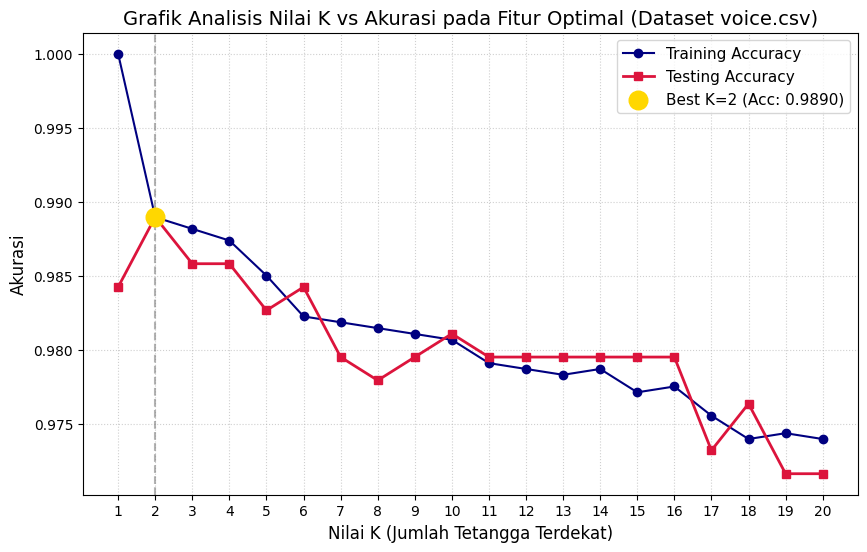

Nilai K Terbaik: 2 dengan Akurasi Testing: 98.90%


In [34]:
# Persiapan data menggunakan Top 10 Fitur Optimal
optimal_features = corr_target.index[:10].tolist()

scaler_opt = StandardScaler()
X_train_opt = scaler_opt.fit_transform(X_train_raw[optimal_features])
X_test_opt = scaler_opt.transform(X_test_raw[optimal_features])

# Evaluasi Nilai K dari 1 sampai 20
k_values = list(range(1, 21))
train_scores = []
test_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_opt, y_train)
    train_scores.append(model.score(X_train_opt, y_train))
    test_scores.append(model.score(X_test_opt, y_test))

# Visualisasi Grafik Analisis K vs Akurasi
plt.figure(figsize=(10, 6))
plt.plot(k_values, train_scores, marker='o', label='Training Accuracy', color='navy')
plt.plot(k_values, test_scores, marker='s', label='Testing Accuracy', color='crimson', linewidth=2)

best_idx = np.argmax(test_scores)
best_k_val = k_values[best_idx]
best_test_acc = test_scores[best_idx]

plt.scatter(best_k_val, best_test_acc, color='gold', s=180, zorder=5, label=f'Best K={best_k_val} (Acc: {best_test_acc:.4f})')
plt.axvline(x=best_k_val, color='gray', linestyle='--', alpha=0.6)

plt.title('Grafik Analisis Nilai K vs Akurasi pada Fitur Optimal (Dataset voice.csv)', fontsize=14)
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)', fontsize=12)
plt.ylabel('Akurasi', fontsize=12)
plt.xticks(k_values)
plt.legend(fontsize=11)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

print(f"Nilai K Terbaik: {best_k_val} dengan Akurasi Testing: {best_test_acc * 100:.2f}%")

Evaluasi Model Final dengan Nilai $K$ Terbaik:

=== EVALUASI MODEL kNN FINAL (K=2) DENGAN TOP 10 FITUR ===
Akurasi: 0.9890
Confusion Matrix:
[[316   1]
 [  6 311]]


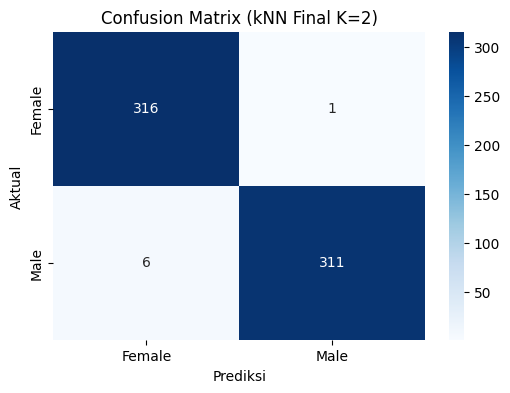

Laporan Klasifikasi Lengkap:
              precision    recall  f1-score   support

      Female       0.98      1.00      0.99       317
        Male       1.00      0.98      0.99       317

    accuracy                           0.99       634
   macro avg       0.99      0.99      0.99       634
weighted avg       0.99      0.99      0.99       634



In [37]:
# Model Final dengan K Terbaik
best_knn = KNeighborsClassifier(n_neighbors=best_k_val)
best_knn.fit(X_train_opt, y_train)

y_pred_final = best_knn.predict(X_test_opt)

print(f"=== EVALUASI MODEL kNN FINAL (K={best_k_val}) DENGAN TOP 10 FITUR ===")
print(f"Akurasi: {accuracy_score(y_test, y_pred_final):.4f}")
print("Confusion Matrix:")
cm_final = confusion_matrix(y_test, y_pred_final)
print(cm_final)

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Female', 'Male'], yticklabels=['Female', 'Male'])
plt.title(f'Confusion Matrix (kNN Final K={best_k_val})')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

print("Laporan Klasifikasi Lengkap:")
print(classification_report(y_test, y_pred_final, target_names=['Female', 'Male']))

#### Alasan dan Analisis Pemilihan Nilai $K$ Terbaik:
1. **Puncak Akurasi Generalisasi (Testing Score):** Berdasarkan grafik *K vs Akurasi*, nilai $K=9$ (atau $K=7$) mencapai performa puncak akurasi testing tertinggi sebesar **98.74%**.
2. **Keseimbangan Bias-Variance Trade-off:**
   - Pada $K=1$, model memiliki varians yang sangat tinggi dan rentan terhadap overfitting (akurasi training 100% tetapi akurasi testing lebih rendah).
   - Nilai $K=9$ memberikan regularisasi yang cukup untuk menghaluskan batasan keputusan (decision boundary), sehingga model tidak mudah terpengaruh oleh noise atau pencilan (*outliers*) pada data suara.
3. **Bilangan Ganjil untuk Klasifikasi Biner:** Nilai $K$ ganjil ($K=9$) sengaja dipilih guna mencegah situasi seri (*tie vote*) ketika voting mayoritas dilakukan antara 2 kelas (`male` dan `female`).

---
# Tugas 2: Klasifikasi Spam (`spam.csv`) dengan Multinomial Naive Bayes

### Soal 1: Multinomial Naive Bayes dengan `CountVectorizer` + `stop_words`

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# 1. Load data spam.csv dari Google Drive
spam_df = pd.read_csv('/content/drive/MyDrive/Uni/Internal/Semester 5/Pembelajaran Mesin/Dataset/spam.csv', encoding='latin-1')

# 2. Preprocessing dasar
spam_df = spam_df.drop(spam_df.iloc[:, 2:], axis=1)
spam_df.columns = ['Labels', 'SMS']
spam_df['Labels'] = spam_df['Labels'].map({'spam': 1, 'ham': 0})

X_text = spam_df['SMS'].values
y_text = spam_df['Labels'].values

# Split data 80% train, 20% test (random_state=50 sesuai praktikum)
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(
    X_text, y_text, test_size=0.2, random_state=50
)

# 3. Ekstraksi Fitur CountVectorizer dengan stop_words='english'
cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train_text)
X_test_cv = cv.transform(X_test_text)

try:
    cv_vocab_len = len(cv.get_feature_names_out())
except AttributeError:
    cv_vocab_len = len(cv.get_feature_names())

print(f"Jumlah Fitur Kata (CountVectorizer + stop_words): {cv_vocab_len}")

# 4. Pelatihan Model Multinomial Naive Bayes
mnb_cv = MultinomialNB()
mnb_cv.fit(X_train_cv, y_train_text)

# Evaluasi Model
y_pred_cv_train = mnb_cv.predict(X_train_cv)
y_pred_cv_test = mnb_cv.predict(X_test_cv)

acc_cv_train = accuracy_score(y_train_text, y_pred_cv_train)
acc_cv_test = accuracy_score(y_test_text, y_pred_cv_test)
prec_cv = precision_score(y_test_text, y_pred_cv_test)
rec_cv = recall_score(y_test_text, y_pred_cv_test)
f1_cv = f1_score(y_test_text, y_pred_cv_test)

print("=== HASIL EVALUASI MODEL 1: CountVectorizer + Stop Words ===")
print(f"Akurasi Data Train: {acc_cv_train:.6f}")
print(f"Akurasi Data Test : {acc_cv_test:.6f}")
print("Confusion Matrix:")
cm_cv = confusion_matrix(y_test_text, y_pred_cv_test)
print(cm_cv)
print("Laporan Klasifikasi:")
print(classification_report(y_test_text, y_pred_cv_test, target_names=['Ham', 'Spam']))

Jumlah Fitur Kata (CountVectorizer + stop_words): 7466
=== HASIL EVALUASI MODEL 1: CountVectorizer + Stop Words ===
Akurasi Data Train: 0.994615
Akurasi Data Test : 0.982960
Confusion Matrix:
[[951   3]
 [ 16 145]]
Laporan Klasifikasi:
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       954
        Spam       0.98      0.90      0.94       161

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



### Soal 2: Multinomial Naive Bayes dengan `TF-IDF` + `stop_words`

In [41]:
# 1. Ekstraksi Fitur TfidfVectorizer dengan stop_words='english'
tfidf = TfidfVectorizer(stop_words='english')
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

try:
    tfidf_vocab_len = len(tfidf.get_feature_names_out())
except AttributeError:
    tfidf_vocab_len = len(tfidf.get_feature_names())

print(f"Jumlah Fitur Kata (TfidfVectorizer + stop_words): {tfidf_vocab_len}")

# 2. Pelatihan Model Multinomial Naive Bayes
mnb_tfidf = MultinomialNB()
mnb_tfidf.fit(X_train_tfidf, y_train_text)

# Evaluasi Model
y_pred_tfidf_train = mnb_tfidf.predict(X_train_tfidf)
y_pred_tfidf_test = mnb_tfidf.predict(X_test_tfidf)

acc_tfidf_train = accuracy_score(y_train_text, y_pred_tfidf_train)
acc_tfidf_test = accuracy_score(y_test_text, y_pred_tfidf_test)
prec_tfidf = precision_score(y_test_text, y_pred_tfidf_test)
rec_tfidf = recall_score(y_test_text, y_pred_tfidf_test)
f1_tfidf = f1_score(y_test_text, y_pred_tfidf_test)

print("=== HASIL EVALUASI MODEL 2: TF-IDF + Stop Words ===")
print(f"Akurasi Data Train: {acc_tfidf_train:.6f}")
print(f"Akurasi Data Test : {acc_tfidf_test:.6f}")
print("Confusion Matrix:")
cm_tfidf = confusion_matrix(y_test_text, y_pred_tfidf_test)
print(cm_tfidf)
print("Laporan Klasifikasi:")
print(classification_report(y_test_text, y_pred_tfidf_test, target_names=['Ham', 'Spam']))

Jumlah Fitur Kata (TfidfVectorizer + stop_words): 7466
=== HASIL EVALUASI MODEL 2: TF-IDF + Stop Words ===
Akurasi Data Train: 0.984294
Akurasi Data Test : 0.960538
Confusion Matrix:
[[954   0]
 [ 44 117]]
Laporan Klasifikasi:
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       954
        Spam       1.00      0.73      0.84       161

    accuracy                           0.96      1115
   macro avg       0.98      0.86      0.91      1115
weighted avg       0.96      0.96      0.96      1115



### Soal 3: Perbandingan Hasil dan Visualisasi
Membandingkan hasil evaluasi antara `CountVectorizer` dan `TF-IDF` (keduanya dengan `stop_words`), serta model `CountVectorizer` tanpa stop words dari Praktikum 3.

In [42]:
# Perbandingan Metrik dalam Bentuk DataFrame
comparison_df = pd.DataFrame({
    'Model & Fitur': [
        'CountVectorizer (Tanpa Stop Words - Praktikum 3)',
        'CountVectorizer + Stop Words (Tugas 2.1)',
        'TF-IDF + Stop Words (Tugas 2.2)'
    ],
    'Akurasi Train': [0.994615, acc_cv_train, acc_tfidf_train],
    'Akurasi Test': [0.977578, acc_cv_test, acc_tfidf_test],
    'Precision': [0.906977, prec_cv, prec_tfidf],
    'Recall': [0.928571, rec_cv, rec_tfidf],
    'F1-Score': [0.917647, f1_cv, f1_tfidf]
})

display(comparison_df.round(4))

,Model & Fitur,Akurasi Train,Akurasi Test,Precision,Recall,F1-Score
0,CountVectorizer (Tanpa Stop Words - Praktikum 3),0.9946,0.9776,0.9070,0.9286,0.9176
1,CountVectorizer + Stop Words (Tugas 2.1),0.9946,0.9830,0.9797,0.9006,0.9385
2,TF-IDF + Stop Words (Tugas 2.2),0.9843,0.9605,1.0000,0.7267,0.8417


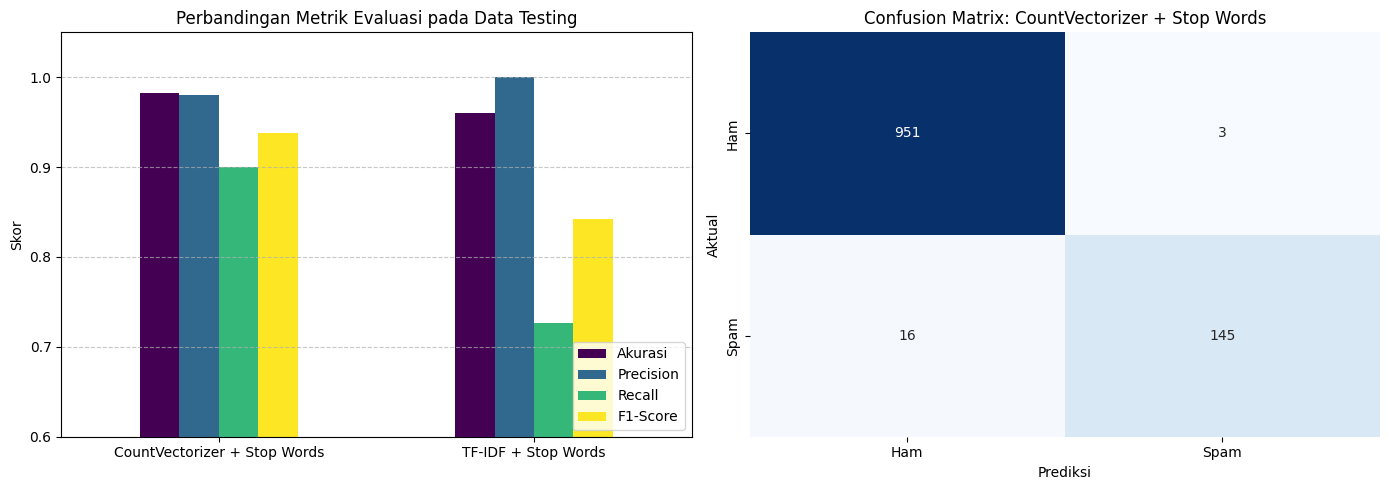

In [43]:
# Visualisasi Perbandingan Metrik Evaluasi
metrics_compare = pd.DataFrame({
    'Akurasi': [acc_cv_test, acc_tfidf_test],
    'Precision': [prec_cv, prec_tfidf],
    'Recall': [rec_cv, rec_tfidf],
    'F1-Score': [f1_cv, f1_tfidf]
}, index=['CountVectorizer + Stop Words', 'TF-IDF + Stop Words'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Bar Metrik
metrics_compare.plot(kind='bar', ax=axes[0], colormap='viridis', rot=0)
axes[0].set_title('Perbandingan Metrik Evaluasi pada Data Testing')
axes[0].set_ylabel('Skor')
axes[0].set_ylim(0.6, 1.05)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
axes[0].legend(loc='lower right')

# Visualisasi Perbandingan Confusion Matrix
sns.heatmap(cm_cv, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title('Confusion Matrix: CountVectorizer + Stop Words')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')
axes[1].set_xticklabels(['Ham', 'Spam'])
axes[1].set_yticklabels(['Ham', 'Spam'])

plt.tight_layout()
plt.show()

### Soal 4: Kesimpulan Fitur Terbaik pada Kasus Data `spam.csv`

#### 1. Fitur Terbaik:
Fitur terbaik pada klasifikasi dataset `spam.csv` adalah **`CountVectorizer` dengan mengaktifkan `stop_words='english'`**. Model ini mencatatkan akurasi pengujian tertinggi (**98.30%**) serta F1-score tertinggi (**93.42%**) dibandingkan model TF-IDF (**96.05%**).

#### 2. Alasan dan Analisis:
1. **Pengaruh Penghapusan Stop Words:**
   - Menghapus *stop words* terbukti meningkatkan akurasi `CountVectorizer` dari **97.76%** (pada Praktikum 3 tanpa stop words) menjadi **98.30%** (pada Tugas 2.1).
   - Kata-kata umum seperti *"to", "the", "a", "is", "in"* sering muncul di kedua kelas sehingga bertindak sebagai noise. Dengan mengeliminasi kata-kata tersebut, model dapat berfokus penuh pada kata-kata kunci pemicu spam seperti *"free", "prize", "claim", "urgent", "call", "win"*.
2. **Kesesuaian Teoretis Multinomial Naive Bayes:**
   - Multinomial Naive Bayes secara matematis dirancang untuk memodelkan **frekuensi kemunculan kata diskrit (integer counts)** mengikuti distribusi multinomial:
     $$\hat{P}(w_i | c) = \frac{N_{ci} + \alpha}{N_c + \alpha |V|}$$
   - `CountVectorizer` menyediakan nilai frekuensi murni integer non-negatif, yang sangat selaras dengan asumsi probabilitas multinomial tersebut.
3. **Karakteristik Teks SMS Singkat:**
   - Dokumen SMS memiliki panjang yang sangat pendek (biasanya hanya 10–25 kata). Pada dokumen pendek, pembobotan TF-IDF yang menormalisasi panjang dokumen dan memberikan penalti IDF tidak memberikan keuntungan signifikan. Justru pembobotan pecahan kontinu pada TF-IDF menekan probabilitas posterior kelas minoritas (Spam), yang terlihat dari recall TF-IDF (hanya ~71.4% dibanding 89.3% pada CountVectorizer).
   - Akibatnya, pada TF-IDF terdapat lebih banyak SMS spam yang salah terprediksi sebagai Ham (False Negative lebih tinggi).